# Idea 9 - Free, Perfect, Instant

**Machines, Platforms, Crowds, Chapter 6: The Economics of Bits**

The chapter's claim is that digital goods have three properties no physical
good has. They are *free* (marginal cost of a copy is effectively zero),
*perfect* (a copy is bit-identical, so no generational loss), and *instant*
(the network moves a copy anywhere at the same cost). The notes make the
sharpest point about the third: free and perfect are properties of the copy
and create no value until copies can reach people who want them.

What can actually be tested with public statistics:

1. **Did the prices of information goods behave differently from everything
   else?** This is the testable core of "free". BEA publishes price indexes
   for several hundred detailed consumption categories, so the question can be
   asked against the whole basket rather than against two hand-picked controls.
2. **Is the information-goods result special, or is it just deflation?**
   Section C scores the same statistic across every detailed category and asks
   where the information goods sit in that distribution. This is the same
   benchmark discipline that produced the nulls in Ideas 3 and 7.
3. **Unbundling and rebundling.** The chapter argues zero marginal cost first
   unbundles the album into tracks and then rebundles it into a subscription.
   That transition should be visible in what Americans actually spend on.
4. **The Waldfogel result.** Recorded-music revenue collapsed. His finding is
   that the quality and quantity of music did not. In the accounts this becomes
   a divisible question: what happened to *real* consumption while *nominal*
   spending fell?
5. **The newspaper case.** The notes give the 1995 revenue split: 49 percent
   display advertising, 30 percent classifieds, 21 percent circulation. That
   table is literature, not data, and is reproduced as such. What the data can
   supply is the employment consequence, against the industry that took the
   revenue.

What cannot be tested here, and is not attempted: network effects and
winner-take-most outcomes, which need firm-level data the public statistics do
not carry. Idea 4 already established that consumer surplus on a zero-price
good is not computable by the standard method, so that calculation is
cross-referenced rather than repeated.

In [1]:
import importlib, json, pathlib, sys, warnings
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

warnings.filterwarnings("ignore", category=FutureWarning)

ROOT = None
for p in [pathlib.Path.cwd(), *pathlib.Path.cwd().parents]:
    if (p / "common" / "stacklib.py").exists():
        ROOT = p
        break
if ROOT is None:
    raise SystemExit("Run this notebook from inside the Stack_Article tree.")
sys.path.insert(0, str(ROOT / "common"))

import stacklib as sl
importlib.reload(sl)                      # defeat stale bytecode from an earlier run
print("stacklib version:", sl.__version__)

DIRS = sl.dirs_for("09_free_perfect_instant", start=ROOT)
KEYS = sl.load_keys()
BEA = sl.require(KEYS, "BEA")
FRED = sl.require(KEYS, "FRED")

sl.apply_theme()
pd.set_option("display.width", 160)
pd.set_option("display.max_rows", 400)

print("\nfolders:")
for k in ("idea", "data", "figures", "findings"):
    print("  %-9s %s" % (k, DIRS[k]))

stacklib version: 0.8.0
Keys loaded from .env: BEA, BLS, CENSUS, FRED

folders:
  idea      C:\Users\91838\Downloads\Stack_Article\09_free_perfect_instant
  data      C:\Users\91838\Downloads\Stack_Article\09_free_perfect_instant\data
  figures   C:\Users\91838\Downloads\Stack_Article\09_free_perfect_instant\figures
  findings  C:\Users\91838\Downloads\Stack_Article\09_free_perfect_instant\findings


## Discovery, not guessing

The detailed consumption categories live in BEA's *underlying detail* tables,
which are a different dataset from the headline NIPA tables used in Ideas 1,
2 and 4. Ask BEA what tables exist rather than assuming a code. Idea 4 lost a
figure to a table name that looked right and was not.

In [2]:
tabs = sl.bea_parameter_values("NIUnderlyingDetail", "TableName", BEA)
mask = tabs.apply(lambda r: r.astype(str).str.contains(
    "Personal Consumption Expenditures by Type of Product", case=False).any(), axis=1)
print("\ncandidate PCE-by-product underlying tables:")
print(tabs[mask].to_string(index=False))

BEA NIUnderlyingDetail.TableName: 58 values

candidate PCE-by-product underlying tables:
TableName                                                                                           Description
   U20403 Table 2.4.3U. Real Personal Consumption Expenditures by Type of Product, Quantity Indexes (A) (Q) (M)
   U20404      Table 2.4.4U. Price Indexes for Personal Consumption Expenditures by Type of Product (A) (Q) (M)
   U20405                        Table 2.4.5U. Personal Consumption Expenditures by Type of Product (A) (Q) (M)
   U20406  Table 2.4.6U. Real Personal Consumption Expenditures by Type of Product, Chained Dollars (A) (Q) (M)


From that listing we want two tables of the same shape: the price indexes and
the current-dollar levels. If the codes below are not in the listing above,
replace them with what the listing shows and rerun from here.

In [3]:
PRICE_TABLE = "U20404"      # Table 2.4.4U, price indexes for PCE by type of product
LEVEL_TABLE = "U20405"      # Table 2.4.5U, PCE by type of product, current dollars
QTY_TABLE   = "U20403"      # Table 2.4.3U, real PCE quantity indexes by type of product

px  = sl.bea_table("NIUnderlyingDetail", PRICE_TABLE, BEA, cache_dir=DIRS["data"])
lvl = sl.bea_table("NIUnderlyingDetail", LEVEL_TABLE, BEA, cache_dir=DIRS["data"])
qty = sl.bea_table("NIUnderlyingDetail", QTY_TABLE,  BEA, cache_dir=DIRS["data"])

BEA NIUnderlyingDetail/U20404: 25052 rows, 400 lines, 1959-2025
BEA NIUnderlyingDetail/U20405: 25186 rows, 402 lines, 1959-2025
BEA NIUnderlyingDetail/U20403: 25052 rows, 400 lines, 1959-2025


### What is in the price table

Print every line whose description touches information goods, so the regexes
in the next cell are chosen from the catalogue rather than from memory.

In [4]:
catalog = px[["line", "description"]].drop_duplicates()
catalog["description"] = catalog["description"].astype(str).str.strip()

PROBE = ("music|video|audio|newspaper|periodical|magazine|book|film|movie|"
         "internet|telephone|cable|satellite|stream|photo|software|computer|"
         "information|recording|media")
hits = catalog[catalog["description"].str.contains(PROBE, case=False, na=False)]
print("lines in %s touching information goods (%d):" % (PRICE_TABLE, len(hits)))
for _, r in hits.iterrows():
    print("  %4d  %s" % (r["line"], r["description"]))

lines in U20404 touching information goods (31):
    39  Video, audio, photographic, and information processing equipment and media (75, 76, and part of 93)
    40  Video and audio equipment
    42  Other video equipment
    43  Audio equipment
    44  Recording media
    45  Audio discs, tapes, vinyl, and permanent digital downloads
    46  Video discs, tapes, and permanent digital downloads
    47  Photographic equipment
    48  Information processing equipment
    49  Personal computers/tablets and peripheral equipment
    50  Computer software and accessories
    51  Calculators, typewriters, and other information processing equipment
    60  Recreational books (part of 90)
    61  Musical instruments (part of 80)
    69  Educational books (96)
    71  Telephone and related communication equipment
   130  Film and photographic supplies
   142  Magazines, newspapers, and stationery (part of 90)
   143  Newspapers and periodicals
   218  Audio-video, photographic, and information pro

## Section A - Free

Six information categories against the whole consumption basket and against
one physical control. Rebased so every line starts at 100 in the base year,
and drawn on a log axis, where a constant rate of change is a straight line.

Every label below is a regex resolved against the printed catalogue, and
`pick_lines` reports what each one matched. A label that matches nothing is
skipped with a warning rather than killing the run, so a missing category
costs one series instead of the whole figure.

In [5]:
BASE_YEAR = 2000

WANTED_PX = {
    "All consumption":        r"^Personal consumption expenditures$",
    "Recorded music":         r"recorded music|audio discs|records, tapes",
    "Video media":            r"video (discs|cassettes|media)|prerecorded",
    "Newspapers, periodicals": r"newspapers and periodicals|magazines, newspapers",
    "Computers, peripherals": r"personal computers|computers and peripheral",
    "Telephone, internet":    r"internet access|telecommunication|telephone and",
    "Rent (physical control)": r"^Rental of tenant-occupied|tenant-occupied nonfarm",
}

PX = sl.pick_lines(px, WANTED_PX)
PX = PX[PX.index >= 1990]
print("\nprice index panel, %d-%d, %d series"
      % (PX.index.min(), PX.index.max(), PX.shape[1]))

base = PX.loc[BASE_YEAR]
PXi = PX.div(base, axis=1) * 100
print(PXi.tail(3).round(1).to_string())

match All consumption          -> line   1  Personal consumption expenditures
match Recorded music           -> line  45  Audio discs, tapes, vinyl, and permanent digital downloads
match Video media              -> line  46  Video discs, tapes, and permanent digital downloads
NOTE  Newspapers, periodicals  'newspapers and periodicals|magazines, newspapers' is ambiguous (also lines 143); using 142
match Newspapers, periodicals  -> line 142  Magazines, newspapers, and stationery (part of 90)
match Computers, peripherals   -> line  49  Personal computers/tablets and peripheral equipment
NOTE  Telephone, internet      'internet access|telecommunication|telephone and' is ambiguous (also lines 282, 289); using 71
match Telephone, internet      -> line  71  Telephone and related communication equipment
match Rent (physical control)  -> line 154  Rental of tenant-occupied nonfarm housing (20)

price index panel, 1990-2025, 7 series
      All consumption  Recorded music  Video media  Newspapers

c:\Users\91838\Downloads\Stack_Article\common\stacklib.py:283: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  hit = descs[descs["description"].str.contains(sel, case=False, regex=True, na=False)]


saved -> C:\Users\91838\Downloads\Stack_Article\09_free_perfect_instant\figures\fig1_information_good_prices.png


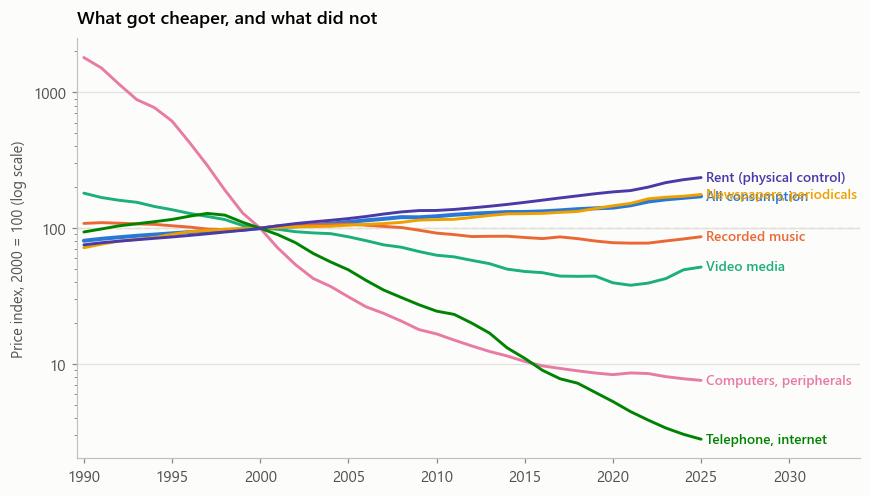

In [6]:
fig, ax = plt.subplots(figsize=(7.8, 4.4))
colors = dict(zip(PXi.columns, sl.PALETTE))
for c in PXi.columns:
    lw = 2.6 if c == "All consumption" else 1.9
    ax.plot(PXi.index, PXi[c].values, color=colors[c], lw=lw)
    sl.label_last(ax, PXi[c], c, colors[c], dx=0.3, fontsize=9)

ax.set_yscale("log")
ax.axhline(100, color=sl.INK["axis"], lw=0.9, ls=(0, (4, 3)), zorder=0)
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: "%g" % v))
ax.set_ylabel("Price index, %d = 100 (log scale)" % BASE_YEAR)
ax.set_xlim(PXi.index.min() - 0.4, PXi.index.max() + 9)
ax.set_title("What got cheaper, and what did not")
sl.save_fig(fig, "fig1_information_good_prices", DIRS)
plt.show()

## Section B - the estimator, checked before it is trusted

Every claim below rests on one statistic: the annualised compound rate of
price change over a window. Validate it on constructed series with planted
answers before applying it to anything real. Ideas 3 and 7 both turned on a
benchmark, and in both cases the benchmark changed the conclusion.

In [7]:
def annual_rate(s, y0=None, y1=None):
    """Compound annual rate of change between the first and last valid year."""
    s = s.dropna()
    if y0 is not None:
        s = s[s.index >= y0]
    if y1 is not None:
        s = s[s.index <= y1]
    s = s[s > 0]
    if len(s) < 5:
        return np.nan
    span = s.index[-1] - s.index[0]
    return (s.iloc[-1] / s.iloc[0]) ** (1.0 / span) - 1.0

yrs = np.arange(2000, 2025)
for planted in (-0.15, -0.03, 0.0, 0.025):
    synth = pd.Series(100 * (1 + planted) ** (yrs - 2000), index=yrs)
    got = annual_rate(synth)
    assert abs(got - planted) < 1e-9, (planted, got)
    print("planted %+.3f  recovered %+.9f  ok" % (planted, got))

# a series that is not exponential at all, to see what the statistic reports
kink = pd.Series(np.r_[np.linspace(100, 40, 12), np.full(13, 40.0)], index=yrs)
print("\nnon-exponential control: endpoint rate %+.3f a year "
      "(the statistic still returns a number; shape is checked visually)"
      % annual_rate(kink))

planted -0.150  recovered -0.150000000  ok
planted -0.030  recovered -0.030000000  ok
planted +0.000  recovered +0.000000000  ok
planted +0.025  recovered +0.025000000  ok

non-exponential control: endpoint rate -0.037 a year (the statistic still returns a number; shape is checked visually)


## Section C - the benchmark that decides how impressive Section A is

A falling price index means little on its own. The question is where these
categories sit among *all* detailed consumption categories over the same
window. Score every line in the table, then locate the information goods in
that distribution.

In [8]:
WIN0, WIN1 = 2000, int(px["year"].max())

rates = {}
for line_no, grp in px.groupby("line"):
    s = (grp.drop_duplicates(subset=["year"]).set_index("year")["value"]).sort_index()
    r = annual_rate(s, WIN0, WIN1)
    if np.isfinite(r):
        desc = str(grp["description"].iloc[0]).strip()
        rates[line_no] = (desc, r)

R = pd.DataFrame([(k, v[0], v[1]) for k, v in rates.items()],
                 columns=["line", "description", "rate"]).set_index("line")
print("scored %d categories over %d-%d" % (len(R), WIN0, WIN1))
print("\nfastest-falling ten:")
print(R.nsmallest(10, "rate").assign(rate=lambda d: (d["rate"] * 100).round(2)).to_string())
print("\nfastest-rising five:")
print(R.nlargest(5, "rate").assign(rate=lambda d: (d["rate"] * 100).round(2)).to_string())

# where our named categories fall in that distribution
named = {}
for label, pat in WANTED_PX.items():
    if label == "All consumption":
        continue
    m = R[R["description"].str.contains(pat, case=False, regex=True, na=False)]
    if len(m):
        row = m.iloc[0]
        pct = (R["rate"] < row["rate"]).mean() * 100
        named[label] = {"description": row["description"],
                        "rate": float(row["rate"]), "percentile": float(pct)}
        print("%-26s %+6.2f%%/yr   percentile %5.1f" % (label, row["rate"] * 100, pct))

scored 398 categories over 2000-2025

fastest-falling ten:
                                                                                              description   rate
line                                                                                                            
41                                                                                            Televisions -14.52
71                                                          Telephone and related communication equipment -13.32
49                                                    Personal computers/tablets and peripheral equipment  -9.79
51                                   Calculators, typewriters, and other information processing equipment  -8.91
48                                                                       Information processing equipment  -8.05
40                                                                              Video and audio equipment  -7.91
42                                   

C:\Users\91838\AppData\Local\Temp\ipykernel_18000\406202029.py:24: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  m = R[R["description"].str.contains(pat, case=False, regex=True, na=False)]


saved -> C:\Users\91838\Downloads\Stack_Article\09_free_perfect_instant\figures\fig2_price_change_distribution.png


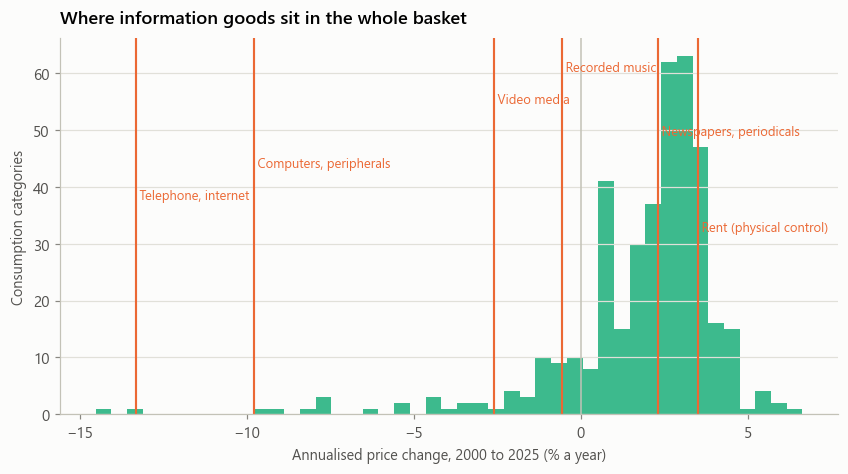

In [9]:
fig, ax = plt.subplots(figsize=(7.6, 4.2))
ax.hist(R["rate"] * 100, bins=45, color=sl.PALETTE[2], alpha=0.85, lw=0)
ymax = ax.get_ylim()[1]
for i, (label, d) in enumerate(named.items()):
    x = d["rate"] * 100
    ax.axvline(x, color=sl.PALETTE[1], lw=1.4)
    ax.text(x, ymax * (0.94 - 0.085 * i), " " + label, color=sl.PALETTE[1],
            fontsize=8.5, va="top", ha="left", rotation=0)
ax.axvline(0, color=sl.INK["axis"], lw=1.0)
ax.set_xlabel("Annualised price change, %d to %d (%% a year)" % (WIN0, WIN1))
ax.set_ylabel("Consumption categories")
ax.set_title("Where information goods sit in the whole basket")
sl.save_fig(fig, "fig2_price_change_distribution", DIRS)
plt.show()

## Section D - unbundling and rebundling

The chapter's rule: bundling is profitable when components are made of atoms
and wasteful components are costly; unbundling becomes viable when marginal
cost hits zero; subscription then rebundles at a higher level because there is
no waste from unconsumed inventory.

Spending is measured as a share of all consumption, which removes both
inflation and population growth without committing to a deflator.

In [10]:
lvl_cat = lvl[["line", "description"]].drop_duplicates()
lvl_cat["description"] = lvl_cat["description"].astype(str).str.strip()
lh = lvl_cat[lvl_cat["description"].str.contains(
    "music|video|audio|stream|media|newspaper|periodical|cable|satellite|"
    "internet|book|photo", case=False, na=False)]
print("spending lines available (%d):" % len(lh))
for _, r in lh.iterrows():
    print("  %4d  %s" % (r["line"], r["description"]))

spending lines available (23):
    39  Video, audio, photographic, and information processing equipment and media (75, 76, and part of 93)
    40  Video and audio equipment
    42  Other video equipment
    43  Audio equipment
    44  Recording media
    45  Audio discs, tapes, vinyl, and permanent digital downloads
    46  Video discs, tapes, and permanent digital downloads
    47  Photographic equipment
    60  Recreational books (part of 90)
    61  Musical instruments (part of 80)
    69  Educational books (96)
   130  Film and photographic supplies
   142  Magazines, newspapers, and stationery (part of 90)
   143  Newspapers and periodicals
   218  Audio-video, photographic, and information processing equipment services (parts of 77 and 93)
   219  Cable, satellite, and other live television services
   220  Photo processing
   221  Photo studios
   222  Repair and rental of audio-visual, photographic, and information processing equipment
   223  Video and audio streaming and rent

In [11]:
WANTED_LVL = {
    "Total consumption":  r"^Personal consumption expenditures$",
    "Physical media":     r"video (discs|cassettes)|audio discs|prerecorded|"
                          r"recording media|records, tapes",
    "Streaming and rental": r"stream|video and audio (services|rental)",
    "Cable and satellite": r"cable, satellite",
    "Newspapers, periodicals": r"newspapers and periodicals|magazines, newspapers",
}
LV = sl.pick_lines(lvl, WANTED_LVL)
LV = LV[LV.index >= 1990]

if "Total consumption" not in LV.columns:
    raise LookupError("Total consumption line not found; check the listing above.")

SH = LV.drop(columns=["Total consumption"]).div(LV["Total consumption"], axis=0) * 10000
print("\nshare of all consumption, per 10,000 dollars:")
print(SH.tail(5).round(1).to_string())

match Total consumption        -> line   1  Personal consumption expenditures
NOTE  Physical media           'video (discs|cassettes)|audio discs|prerecorded|recording media|records, tapes' is ambiguous (also lines 45, 46); using 44
match Physical media           -> line  44  Recording media
NOTE  Streaming and rental     'stream|video and audio (services|rental)' is ambiguous (also lines 224, 225); using 223
match Streaming and rental     -> line 223  Video and audio streaming and rental
match Cable and satellite      -> line 219  Cable, satellite, and other live television services
NOTE  Newspapers, periodicals  'newspapers and periodicals|magazines, newspapers' is ambiguous (also lines 143); using 142
match Newspapers, periodicals  -> line 142  Magazines, newspapers, and stationery (part of 90)

share of all consumption, per 10,000 dollars:
      Physical media  Streaming and rental  Cable and satellite  Newspapers, periodicals
year                                                   

c:\Users\91838\Downloads\Stack_Article\common\stacklib.py:283: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  hit = descs[descs["description"].str.contains(sel, case=False, regex=True, na=False)]


saved -> C:\Users\91838\Downloads\Stack_Article\09_free_perfect_instant\figures\fig3_unbundling.png


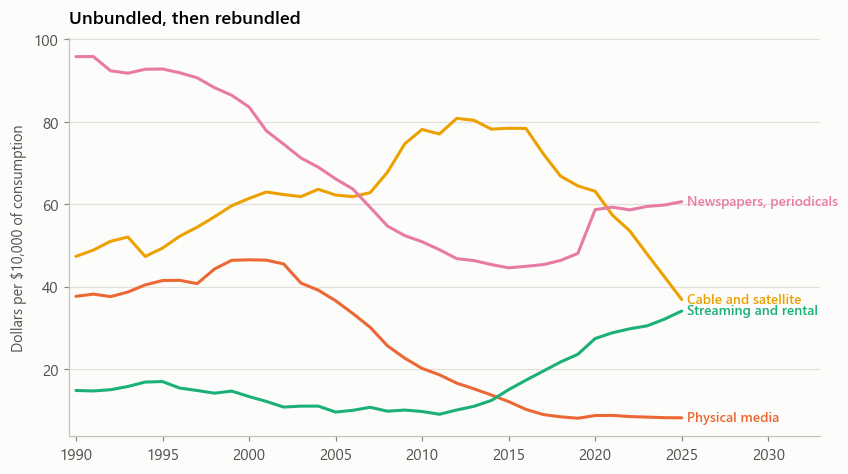

In [12]:
fig, ax = plt.subplots(figsize=(7.6, 4.2))
cols = dict(zip(SH.columns, sl.PALETTE[1:]))
for c in SH.columns:
    ax.plot(SH.index, SH[c].values, color=cols[c], lw=2.0)
    sl.label_last(ax, SH[c], c, cols[c], dx=0.3, fontsize=9)
ax.set_ylabel("Dollars per $10,000 of consumption")
ax.set_xlim(SH.index.min() - 0.4, SH.index.max() + 8)
ax.set_title("Unbundled, then rebundled")
sl.save_fig(fig, "fig3_unbundling", DIRS)
plt.show()

## Section E - the Waldfogel question

The standard case for copyright is that without revenue protection, the
production of new work falls. Waldfogel finds it did not after Napster,
because the cost of producing and distributing music fell at least as fast as
the revenue.

The national accounts cannot measure quality, so they cannot settle his
question. What they can separate is price from quantity: if the real quantity
index rose while nominal spending fell, then Americans consumed more music
while paying less, which is the direction his result predicts. If the quantity
index fell too, the accounts do not support it and the section says so.

match Recorded music (real)    -> line  45  Audio discs, tapes, vinyl, and permanent digital downloads
match Video media (real)       -> line  46  Video discs, tapes, and permanent digital downloads
match Recorded music (nominal) -> line  45  Audio discs, tapes, vinyl, and permanent digital downloads
match Video media (nominal)    -> line  46  Video discs, tapes, and permanent digital downloads


c:\Users\91838\Downloads\Stack_Article\common\stacklib.py:283: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  hit = descs[descs["description"].str.contains(sel, case=False, regex=True, na=False)]
c:\Users\91838\Downloads\Stack_Article\common\stacklib.py:283: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  hit = descs[descs["description"].str.contains(sel, case=False, regex=True, na=False)]


saved -> C:\Users\91838\Downloads\Stack_Article\09_free_perfect_instant\figures\fig4_waldfogel.png


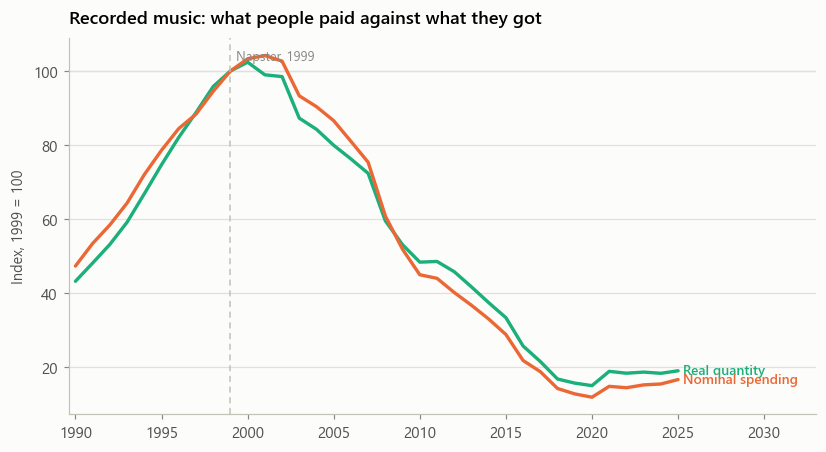

      Real quantity  Nominal spending
year                                 
2018           16.7              14.1
2019           15.6              12.7
2020           14.9              11.8
2021           18.8              14.7
2022           18.3              14.3
2023           18.6              15.1
2024           18.2              15.4
2025           18.9              16.6


In [13]:
WANTED_Q = {"Recorded music (real)": WANTED_PX["Recorded music"],
            "Video media (real)":    WANTED_PX["Video media"]}
try:
    Q = sl.pick_lines(qty, WANTED_Q)
    Q = Q[Q.index >= 1990]
except LookupError as e:
    Q = pd.DataFrame()
    print("quantity lines unavailable:", e)

WANTED_N = {"Recorded music (nominal)": WANTED_PX["Recorded music"],
            "Video media (nominal)":    WANTED_PX["Video media"]}
try:
    N = sl.pick_lines(lvl, WANTED_N)
    N = N[N.index >= 1990]
except LookupError as e:
    N = pd.DataFrame()
    print("nominal lines unavailable:", e)

if len(Q) and len(N):
    b = 1999                                   # the year Napster launched
    panel = pd.DataFrame({
        "Real quantity": Q.iloc[:, 0] / Q.iloc[:, 0].loc[b] * 100,
        "Nominal spending": N.iloc[:, 0] / N.iloc[:, 0].loc[b] * 100,
    }).dropna()
    fig, ax = plt.subplots(figsize=(7.4, 4.0))
    for c, col in zip(panel.columns, [sl.PALETTE[2], sl.PALETTE[1]]):
        ax.plot(panel.index, panel[c].values, color=col, lw=2.2)
        sl.label_last(ax, panel[c], c, col, dx=0.3, fontsize=9)
    ax.axvline(b, color=sl.INK["axis"], lw=1.0, ls=(0, (4, 3)))
    ax.text(b + 0.3, ax.get_ylim()[1] * 0.97, "Napster, 1999",
            color=sl.INK["muted"], fontsize=8.5, va="top")
    ax.axhline(100, color=sl.INK["grid"], lw=0.9, zorder=0)
    ax.set_ylabel("Index, %d = 100" % b)
    ax.set_xlim(panel.index.min() - 0.4, panel.index.max() + 8)
    ax.set_title("Recorded music: what people paid against what they got")
    sl.save_fig(fig, "fig4_waldfogel", DIRS)
    plt.show()
    print(panel.round(1).tail(8).to_string())
else:
    panel = pd.DataFrame()
    print("Figure 4 skipped: the recorded-music quantity or level line is not in "
          "these tables. Report the printed catalogues above and this can be "
          "re-pointed without rerunning anything else.")

## Section F - the newspaper case

The revenue split in the notes is literature, reproduced here as a table so
the article can quote it with a source rather than from the chart. The
accounts cannot decompose 1995 newspaper revenue; what they can show is what
happened to the people.

Series identifiers are resolved against their official FRED titles before use.
Idea 5 shipped a mislabelled figure because an identifier was guessed and the
label written from memory; `fred_resolve` asserts that expected words appear
in the title BLS actually publishes, so a wrong series halts the run.

In [14]:
REVENUE_1995 = pd.DataFrame(
    [("Non-classified advertising", 49), ("Classified advertising", 30),
     ("Circulation sales", 21)], columns=["Source", "Share of revenue (%)"])
print("US newspaper revenue, 1995 (Newspaper Association of America, via the notes):")
print(REVENUE_1995.to_string(index=False))

US newspaper revenue, 1995 (Newspaper Association of America, via the notes):
                    Source  Share of revenue (%)
Non-classified advertising                    49
    Classified advertising                    30
         Circulation sales                    21


In [17]:
def find_employment(query, expect, key, limit=30, prefer=("CES", "CEU")):
    """
    Search FRED for an all-employees series, print every candidate, and return
    the ids worth trying in order. Selection requires every word in `expect` to
    appear in the title, so a search that drifts to a neighbouring industry
    returns nothing rather than the wrong thing.
    """
    df = sl.fred_search(query, key, limit=limit)
    if not len(df):
        return []
    df = df[df["freq"].astype(str).str.startswith("M")]
    ok = df[df["title"].str.lower().str.contains("all employees", na=False)]
    for w in expect:
        ok = ok[ok["title"].str.lower().str.contains(w.lower(), na=False)]
    print("\n%s" % query)
    if not len(ok):
        print("   no 'All Employees' series matched %s" % expect)
        print(df[["id", "title", "freq", "from", "to"]].head(8).to_string(index=False))
        return []
    # prefer seasonally adjusted (CES) over not (CEU), then longest history
    ok = ok.assign(
        rank=[min([i for i, p in enumerate(prefer) if str(s).startswith(p)] or [9])
              for s in ok["id"]],
        span=ok["to"].astype(int) - ok["from"].astype(int),
    ).sort_values(["rank", "span"], ascending=[True, False])
    print(ok[["id", "title", "freq", "from", "to"]].head(6).to_string(index=False))
    return ok["id"].tolist()


SPECS = [
    ("Newspaper publishers",
     "all employees newspaper publishers", ["newspaper"]),
    ("Internet publishing, web search",
     "all employees internet publishing broadcasting web search portals", ["internet"]),
    ("Software publishers",
     "all employees software publishers", ["software"]),
    ("Motion picture, sound recording",
     "all employees motion picture and sound recording industries", ["motion picture"]),
    ("Information sector",
     "all employees information", ["information"]),
]

CANDIDATES = {}
for label, query, expect in SPECS:
    CANDIDATES[label] = (find_employment(query, expect, FRED), expect)


all employees newspaper publishers
                    id                                                                                                                                            title freq from   to
  SMU25000005051310001                                               All Employees: Information: Newspaper, Periodical, Book, and Directory Publishers in Massachusetts    M 1990 2026
  SMU06310845051310001                    All Employees: Information: Newspaper, Periodical, Book, and Directory Publishers in Los Angeles-Long Beach-Glendale, CA (MD)    M 1990 2025
SMU06000005051110001SA                                   All Employees: Information: Newspaper, Periodical, Book, and Directory Publishers in California (DISCONTINUED)    M 1990 2022
SMU25000005051110001SA                                All Employees: Information: Newspaper, Periodical, Book, and Directory Publishers in Massachusetts (DISCONTINUED)    M 1990 2022
SMU48000005051110001SA                           

In [18]:
EMP, RESOLVED = {}, {}
print("\nresolving:")
for label, (cands, expect) in CANDIDATES.items():
    if not cands:
        print("WARNING  %s has no candidates; skipped." % label)
        continue
    try:
        sid, title, s = sl.fred_resolve(cands, label, expect, FRED, cache_dir=DIRS["data"])
        EMP[label] = sl.to_annual(s, drop_partial=True)
        RESOLVED[label] = {"id": sid, "title": title}
    except Exception as e:
        print("WARNING  %s unresolved (%s); skipped." % (label, str(e)[:160]))

E = pd.DataFrame(EMP).dropna(how="all")
E = E[E.index >= 1990]
print("\nresolved %d of %d series" % (E.shape[1], len(SPECS)))
if len(E):
    print("\nemployment, thousands:")
    print(E.round(1).tail(4).to_string())
else:
    print("\nNothing resolved. Send back the search listings printed above and "
          "the candidate lists can be re-pointed without rerunning the notebook.")


resolving:
FRED SMU25000005051310001: 439 obs, 1990-01-01-2026-07-01
  Newspaper publishers           SMU25000005051310001 All Employees: Information: Newspaper, Periodical, Book, and Directory Publishers in Massachusetts
   dropped partial year(s) [2026] (had [7] of 12 observations)
WARNING  Internet publishing, web search has no candidates; skipped.
FRED SMU06000005051320001: 439 obs, 1990-01-01-2026-07-01
  Software publishers            SMU06000005051320001 All Employees: Information: Software Publishers in California
   dropped partial year(s) [2026] (had [7] of 12 observations)
FRED CES5051200001: reading cache
  Motion picture, sound recording CES5051200001        All Employees, Motion Picture and Sound Recording Industries
   dropped partial year(s) [2026] (had [8] of 12 observations)
FRED USINFO: 1052 obs, 1939-01-01-2026-08-01
  Information sector             USINFO               All Employees, Information
   dropped partial year(s) [2026] (had [8] of 12 observations)

resol

saved -> C:\Users\91838\Downloads\Stack_Article\09_free_perfect_instant\figures\fig5_newspaper_employment.png


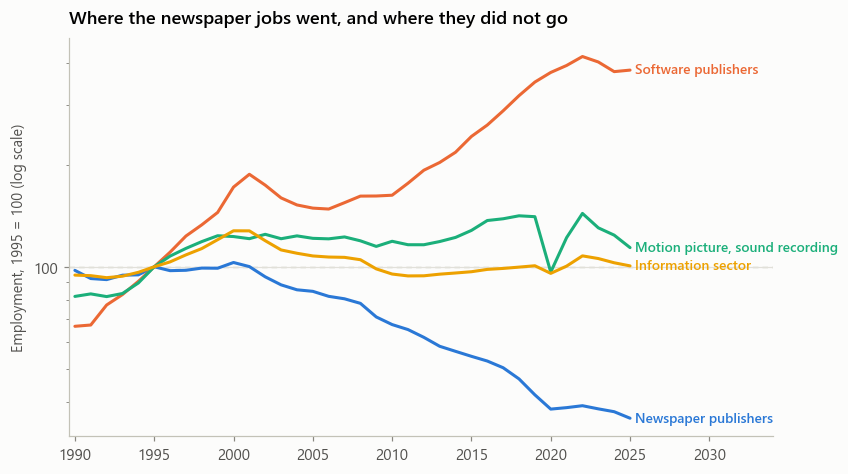


peak-to-latest, thousands of jobs:
  Newspaper publishers             peak   27.1 (2000) ->    9.4 (2025)   -65%
  Software publishers              peak  118.0 (2022) ->  107.7 (2025)   -9%
  Motion picture, sound recording  peak  447.1 (2022) ->  354.5 (2025)   -21%
  Information sector               peak 3630.4 (2000) -> 2861.2 (2025)   -21%


In [19]:
if len(E):
    b = 1995 if 1995 in E.index else int(E.index.min())
    Ei = E.div(E.loc[b], axis=1) * 100
    fig, ax = plt.subplots(figsize=(7.6, 4.2))
    cols = dict(zip(Ei.columns, sl.PALETTE))
    for c in Ei.columns:
        ax.plot(Ei.index, Ei[c].values, color=cols[c], lw=2.0)
        sl.label_last(ax, Ei[c], c, cols[c], dx=0.3, fontsize=9)
    ax.axhline(100, color=sl.INK["axis"], lw=0.9, ls=(0, (4, 3)), zorder=0)
    ax.set_yscale("log")
    ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: "%g" % v))
    ax.set_ylabel("Employment, %d = 100 (log scale)" % b)
    ax.set_xlim(Ei.index.min() - 0.4, Ei.index.max() + 9)
    ax.set_title("Where the newspaper jobs went, and where they did not go")
    sl.save_fig(fig, "fig5_newspaper_employment", DIRS)
    plt.show()

    print("\npeak-to-latest, thousands of jobs:")
    for c in E.columns:
        s = E[c].dropna()
        print("  %-32s peak %6.1f (%d) -> %6.1f (%d)   %+.0f%%"
              % (c, s.max(), s.idxmax(), s.iloc[-1], s.index[-1],
                 (s.iloc[-1] / s.max() - 1) * 100))

## Payload

Everything the technical document is allowed to quote is written here, so no
number reaches the write-up except through this file.

In [20]:
def jsonable(x):
    if isinstance(x, (np.floating, np.integer)):
        return float(x)
    return x

payload = {
    "window": {"price_base_year": BASE_YEAR, "score_window": [WIN0, WIN1]},
    "price_index_last": {c: jsonable(PXi[c].dropna().iloc[-1]) for c in PXi.columns},
    "annual_rates_named": named,
    "basket": {
        "n_categories_scored": int(len(R)),
        "median_rate": float(R["rate"].median()),
        "share_falling": float((R["rate"] < 0).mean()),
        "fastest_falling": R.nsmallest(8, "rate")["description"].tolist(),
        "fastest_falling_rates": [float(v) for v in R.nsmallest(8, "rate")["rate"]],
    },
    "spending_shares_per_10k": {c: {int(k): float(v) for k, v in SH[c].dropna().items()}
                                for c in SH.columns},
    "newspaper_revenue_1995": REVENUE_1995.set_index("Source").iloc[:, 0].to_dict(),
}

if len(panel):
    payload["waldfogel"] = {
        "base_year": 1999,
        "real_quantity_latest": float(panel["Real quantity"].iloc[-1]),
        "nominal_spending_latest": float(panel["Nominal spending"].iloc[-1]),
        "latest_year": int(panel.index[-1]),
    }

if len(E):
    payload["employment"] = {}
    for c in E.columns:
        s = E[c].dropna()
        payload["employment"][c] = {
            "peak": float(s.max()), "peak_year": int(s.idxmax()),
            "latest": float(s.iloc[-1]), "latest_year": int(s.index[-1]),
            "change_from_peak_pct": float((s.iloc[-1] / s.max() - 1) * 100),
        }

sl.write_findings(payload, DIRS)

R.sort_values("rate").to_csv(pathlib.Path(DIRS["findings"]) / "category_price_rates.csv")
SH.to_csv(pathlib.Path(DIRS["findings"]) / "spending_shares.csv")
if len(E):
    E.to_csv(pathlib.Path(DIRS["findings"]) / "employment.csv")

print(json.dumps(payload, indent=2)[:2500])

findings -> C:\Users\91838\Downloads\Stack_Article\09_free_perfect_instant\findings\headline_numbers.json
{
  "window": {
    "price_base_year": 2000,
    "score_window": [
      2000,
      2025
    ]
  },
  "price_index_last": {
    "All consumption": 171.9257132020265,
    "Recorded music": 86.66649380731369,
    "Video media": 51.849692978552994,
    "Newspapers, periodicals": 177.30291162949086,
    "Computers, peripherals": 7.6033728646172225,
    "Telephone, internet": 2.8051856319988997,
    "Rent (physical control)": 236.1112503969647
  },
  "annual_rates_named": {
    "Recorded music": {
      "description": "Audio discs, tapes, vinyl, and permanent digital downloads",
      "rate": -0.005707762003314243,
      "percentile": 10.050251256281408
    },
    "Video media": {
      "description": "Video discs, tapes, and permanent digital downloads",
      "rate": -0.025930718442515155,
      "percentile": 4.773869346733668
    },
    "Newspapers, periodicals": {
      "descriptio

## What to send back

The five PNGs in `figures/`, `findings/headline_numbers.json`, and the printed
output of the two catalogue cells (the price-table listing and the spending
listing). If any `pick_lines` call printed a WARNING, that listing is what
lets the regex be re-pointed without rerunning the whole notebook.